In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [3]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import Input, Layer, Dense, Add, Embedding  # <<<<============ Add Embedding here
from tensorflow.keras.layers import LSTM
# from tensorflow.keras.layers import Activation, Flatten 
from tensorflow.keras.models import Model
from tensorflow.keras import optimizers
from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.util import ngrams
import matplotlib.pyplot as plt


I0000 00:00:1791872453.878372   34782 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791872458.988145   34782 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
sentences = [ 
    "the cat is walking in the bedroom",
    "a dog was running in a room",
    "the cat is running in a room",
    "a dog is walking in a bedroom",
    "the dog was walking in the room"
]

In [5]:
# Data preprocessing
tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)
word2idx = tokenizer.word_index
idx2word = { v:k for (k,v) in word2idx.items()}
sequences = tokenizer.texts_to_sequences(sentences)

In [6]:
print(word2idx)
print(idx2word)
print(sequences)

{'the': 1, 'in': 2, 'a': 3, 'is': 4, 'walking': 5, 'dog': 6, 'room': 7, 'cat': 8, 'bedroom': 9, 'was': 10, 'running': 11}
{1: 'the', 2: 'in', 3: 'a', 4: 'is', 5: 'walking', 6: 'dog', 7: 'room', 8: 'cat', 9: 'bedroom', 10: 'was', 11: 'running'}
[[1, 8, 4, 5, 2, 1, 9], [3, 6, 10, 11, 2, 3, 7], [1, 8, 4, 11, 2, 3, 7], [3, 6, 4, 5, 2, 3, 9], [1, 6, 10, 5, 2, 1, 7]]


In [7]:
n=4 #4 n-grams
list_ngrams = [list(ngrams(s, n)) for s in sequences]
array_ngrams = np.array(list_ngrams).reshape(-1,n)

print(list_ngrams)
print(array_ngrams)

[[(1, 8, 4, 5), (8, 4, 5, 2), (4, 5, 2, 1), (5, 2, 1, 9)], [(3, 6, 10, 11), (6, 10, 11, 2), (10, 11, 2, 3), (11, 2, 3, 7)], [(1, 8, 4, 11), (8, 4, 11, 2), (4, 11, 2, 3), (11, 2, 3, 7)], [(3, 6, 4, 5), (6, 4, 5, 2), (4, 5, 2, 3), (5, 2, 3, 9)], [(1, 6, 10, 5), (6, 10, 5, 2), (10, 5, 2, 1), (5, 2, 1, 7)]]
[[ 1  8  4  5]
 [ 8  4  5  2]
 [ 4  5  2  1]
 [ 5  2  1  9]
 [ 3  6 10 11]
 [ 6 10 11  2]
 [10 11  2  3]
 [11  2  3  7]
 [ 1  8  4 11]
 [ 8  4 11  2]
 [ 4 11  2  3]
 [11  2  3  7]
 [ 3  6  4  5]
 [ 6  4  5  2]
 [ 4  5  2  3]
 [ 5  2  3  9]
 [ 1  6 10  5]
 [ 6 10  5  2]
 [10  5  2  1]
 [ 5  2  1  7]]


In [8]:
# training data
x_train = array_ngrams[:, :-1]
y_train = array_ngrams[:, -1]

In [14]:
m = 8                   # word embedding size vector
V = len(word2idx) + 1   # vocabulary size
r = 64                  # no. of recurrent units

In [ ]:
# ======================= also not needed ===================
# word embedding layer
# class WordEmbedding(Layer):
#     def __init__(self, input_dim, emb_size, name=None):
#         super(WordEmbedding, self).__init__(name=name)

#         # Matrix C registered as a Keras layer weight
#         self.C = self.add_weight(
#             name='C',
#             shape=(input_dim, emb_size),
#             initializer='random_normal',
#             trainable=True
#         )

#     def call(self, x):
#         # Table look up in C
#         selected_rows = tf.gather(self.C, x) # (None, 3, 8)
#         return selected_rows
        

In [16]:
# create NPLM model
x_input = Input(batch_shape = (None, x_train.shape[1]), dtype='int32')
# x_embed = WordEmbedding(V, m, name='emb')(x_input)         <<<<<<<<==========chnage this to below
x_embed = Embedding(input_dim=V, output_dim=m, name='emb')(x_input)   
x_lstm = LSTM(r)(x_embed)
y_output = Dense(V, activation='softmax')(x_lstm)

# ============comment out below============
# x_concat = Flatten()(x_embed)
# Hx = Dense(h, activation='tanh')(x_concat)
# Wx = Dense(V, use_bias = False)(x_concat)
# Ux = Dense(V)(Hx)
# y = Add()([Wx, Ux])
# y_prob = Activation('softmax')(y)

In [19]:
model = Model(x_input, y_output)
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=optimizers.Adam(learning_rate=0.01)
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emb (Embedding)                 │ (None, 3, 8)           │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,564 (76.42 KB)

 Trainable params: 19,564 (76.42 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# fit data to the model
hist = model.fit(x_train, y_train, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 2.4840
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 2.4552
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 2.4178
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 2.3659
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 2.2951
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 2.2021
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 2.0878
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 1.9613
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 1.8426
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 1.7479
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 1.6585
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1.5474
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 1.4169
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 1.2783
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 1.1444
Epoch 16/100
1/1 ━━━━

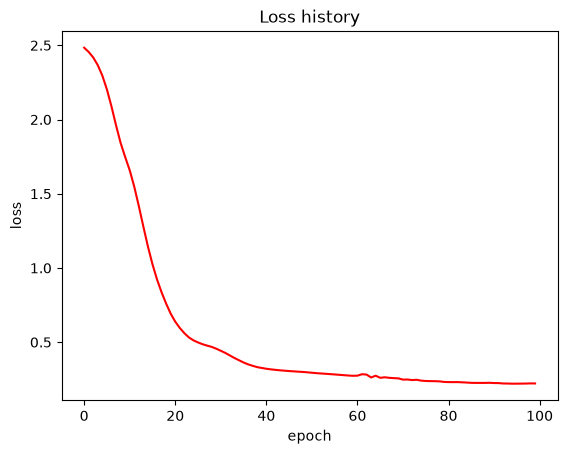

In [21]:
# losss history
plt.plot(hist.history['loss'], color='red')
plt.title("Loss history")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [22]:
# matrix C
C = model.get_layer('emb').get_weights()[0]

In [23]:
# word vector
print("\nWord vectors:")
for word, idx in word2idx.items():
    word_vector = C[idx, :]
    print("{:10s}".format(word), end='')
    print(word_vector.round(3))


Word vectors:
the       [ 0.286  0.623  0.183  0.133 -0.148 -0.073 -0.224 -0.27 ]
in        [ 0.658 -0.364  0.79   0.424 -0.738 -0.442  0.785 -0.74 ]
a         [ 0.304  0.336  0.357  0.173 -0.154 -0.065  0.01  -0.359]
is        [-0.243  0.236 -0.291 -0.433 -0.326  0.398 -0.143  0.218]
walking   [ 0.235 -0.669  0.15  -0.335 -0.374  0.231  0.855 -0.449]
dog       [-0.586  0.397 -0.677 -0.507  0.007  0.497 -0.53   0.55 ]
room      [-0.039 -0.034  0.033  0.044 -0.02  -0.007 -0.019 -0.018]
cat       [-0.267  0.193 -0.344 -0.296 -0.052  0.269 -0.214  0.28 ]
bedroom   [ 0.022 -0.038 -0.013  0.017  0.026 -0.013 -0.005  0.014]
was       [-0.216 -0.279 -0.271 -0.225 -0.027 -0.252  0.174  0.02 ]
running   [ 0.593  0.536  0.413  0.026 -0.722  0.313  0.439 -0.504]


In [24]:
# P(w4 | w1, w2, w3)
print("\nP(w4 | w1, w2, w3):")
x = x_train[0] #"the", "cat", "is"
p = model.predict(
    x.reshape(1, -1),
    verbose=0
)[0]

print(idx2word[x[0]],idx2word[x[1]],idx2word[x[2]], ':')

for word, idx in word2idx.items():
    print("{:10s}: {:.3f}".format(word, p[idx]))


P(w4 | w1, w2, w3):
the cat is :
the       : 0.000
in        : 0.000
a         : 0.001
is        : 0.000
walking   : 0.621
dog       : 0.000
room      : 0.000
cat       : 0.000
bedroom   : 0.000
was       : 0.000
running   : 0.378


In [25]:
# sentence matrix
print("\n sentence matrix:")
i=0
print('sen:', sentences[i], ':')
print(C[sequences[i]].round(2))


 sentence matrix:
sen: the cat is walking in the bedroom :
[[ 0.29  0.62  0.18  0.13 -0.15 -0.07 -0.22 -0.27]
 [-0.27  0.19 -0.34 -0.3  -0.05  0.27 -0.21  0.28]
 [-0.24  0.24 -0.29 -0.43 -0.33  0.4  -0.14  0.22]
 [ 0.23 -0.67  0.15 -0.33 -0.37  0.23  0.85 -0.45]
 [ 0.66 -0.36  0.79  0.42 -0.74 -0.44  0.78 -0.74]
 [ 0.29  0.62  0.18  0.13 -0.15 -0.07 -0.22 -0.27]
 [ 0.02 -0.04 -0.01  0.02  0.03 -0.01 -0.01  0.01]]
